# Traditional NLP & Rule-Based Stance Prediction on the args.me Corpus

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/)

This notebook evaluates how well **traditional rule-based systems** and **classical NLP / machine learning approaches** can predict argument stance (`PRO` vs. `CON`) on the [`webis/args_me`](https://huggingface.co/datasets/webis/args_me) dataset.

### Models Evaluated:
1. **Majority Class Baseline (Zero-R)**
2. **Rule-Based Heuristic Matcher** (Debate cues, rhetorical patterns, sentiment concordance)
3. **VADER Sentiment Polarity Baseline**
4. **Multinomial Naive Bayes** (Premise TF-IDF)
5. **Logistic Regression** (Premise-only TF-IDF & Contextual TF-IDF)
6. **Linear Support Vector Machine (LinearSVC)**
7. **Random Forest** (Engineered dense linguistic, rhetorical & overlap features)
8. **Hybrid Classifier** (Linear SVM on Sparse TF-IDF + Dense Linguistic Features)
9. **Cross-Topic Generalization Test** (Evaluating on completely unseen debate topics)

In [1]:
# 1. Environment & Dependency Setup
import sys
import os
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules or os.path.exists('/content')
if IN_COLAB:
    print("Installing dependencies in Colab runtime...")
    !pip install -q datasets huggingface_hub pandas pyarrow scikit-learn nltk scipy matplotlib seaborn
    import nltk
    nltk.download('vader_lexicon', quiet=True)
    nltk.download('stopwords', quiet=True)
else:
    print("Running in local environment.")

Installing dependencies in Colab runtime...


In [3]:
# Clone the source repository to get the custom 'src' modules
!git clone https://github.com/dustinober1/Arg_Me.git

# Move into the cloned repository folder to execute code correctly
import os
if os.path.exists('Arg_Me'):
    os.chdir('Arg_Me')
    print("Successfully cloned repository and changed workspace directory to /content/Arg_Me")

Cloning into 'Arg_Me'...
remote: Enumerating objects: 41, done.
remote: Counting objects: 100% (41/41), done.
remote: Compressing objects: 100% (30/30), done.
remote: Total 41 (delta 13), reused 34 (delta 8), pack-reused 0 (from 0)
Receiving objects: 100% (41/41), 77.10 KiB | 626.00 KiB/s, done.
Resolving deltas: 100% (13/13), done.
Successfully cloned repository and changed workspace directory to /content/Arg_Me


In [5]:
# 2. Imports and Configuration
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure project root is available
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()))

# NOTE: Please clone your GitHub repository or upload the 'src' directory to Colab first!
from src.dataset_loader import load_sample_df
from src.baseline_stance import StanceBenchmarkRunner, DenseFeatureExtractor, RuleBasedStanceClassifier

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams["figure.figsize"] = (10, 6)

In [6]:
# 3. Load or Stream Evaluation Dataset
data_path = Path("../data/args_me_benchmark_5k.parquet")
if not data_path.exists():
    data_path = Path("data/args_me_benchmark_5k.parquet")

if data_path.exists():
    print(f"Loading cached benchmark from {data_path}...")
    df = pd.read_parquet(data_path)
else:
    print("Streaming 5,000 arguments from args.me...")
    df = load_sample_df(n_records=5000, save_parquet=True, parquet_filename="args_me_benchmark_5k.parquet")

print(f"Loaded {len(df)} records.")
print("\nStance distribution:")
print(df['stance'].value_counts(normalize=True).round(4) * 100)
print(f"\nUnique Debate Topics: {df['conclusion'].nunique()}")

Streaming 5,000 arguments from args.me...
Streaming 5000 records from webis/args_me...
Collected 5000 premise rows across 5000 argument records.
Sample saved to /content/Arg_Me/data/args_me_benchmark_5k.parquet
Loaded 5000 records.

Stance distribution:
stance
CON    50.16
PRO    49.84
Name: proportion, dtype: float64

Unique Debate Topics: 880


In [7]:
# 4. Run Comprehensive Benchmark Suite
runner = StanceBenchmarkRunner(random_state=42)
results_df = runner.run_comprehensive_benchmark(df, test_size=0.20)
results_df

[1/9] Evaluating Majority Baseline (Zero-R)...
[2/9] Evaluating Rule-Based Heuristic Classifier...
[3/9] Evaluating Pure VADER Sentiment Classifier...
[4/9] Evaluating Multinomial Naive Bayes (Premise TF-IDF)...
[5/9] Evaluating Logistic Regression (Premise-only TF-IDF)...
[6/9] Evaluating Logistic Regression (Contextual TF-IDF)...
[7/9] Evaluating Linear SVM (Contextual TF-IDF)...
[8/9] Extracting Dense Linguistic Features & Evaluating Random Forest...
[9/9] Evaluating Hybrid Classifier (TF-IDF + Linguistic Dense Features)...


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


,Model,Accuracy,Macro F1,Macro Precision,Macro Recall,CON F1,PRO F1,ROC-AUC
0,Majority Baseline (Zero-R),0.502,0.3342,0.2510,0.5000,0.6684,0.0000,0.5
1,Rule-Based Heuristic (Cues + Polarity),0.492,0.4902,0.4921,0.4922,0.4596,0.5208,N/A
2,VADER Sentiment Polarity Baseline,0.504,0.4988,0.5046,0.5044,0.4477,0.5499,N/A
3,Multinomial Naive Bayes (Premise TF-IDF),0.511,0.5109,0.5110,0.5110,0.5163,0.5056,0.5257
4,Logistic Regression (Premise TF-IDF),0.538,0.5380,0.5380,0.5380,0.5352,0.5408,0.5565
5,Logistic Regression (Contextual TF-IDF),0.507,0.5070,0.5070,0.5070,0.5104,0.5035,0.5223
6,Linear SVM (Contextual TF-IDF),0.507,0.5067,0.5069,0.5069,0.5181,0.4954,0.5245
7,Random Forest (Linguistic & Stylistic Features),0.511,0.5106,0.5112,0.5111,0.4964,0.5248,0.525
8,Hybrid Model (Linear SVM + TF-IDF + Dense Feat...,0.515,0.5149,0.5150,0.5150,0.5212,0.5086,0.5366


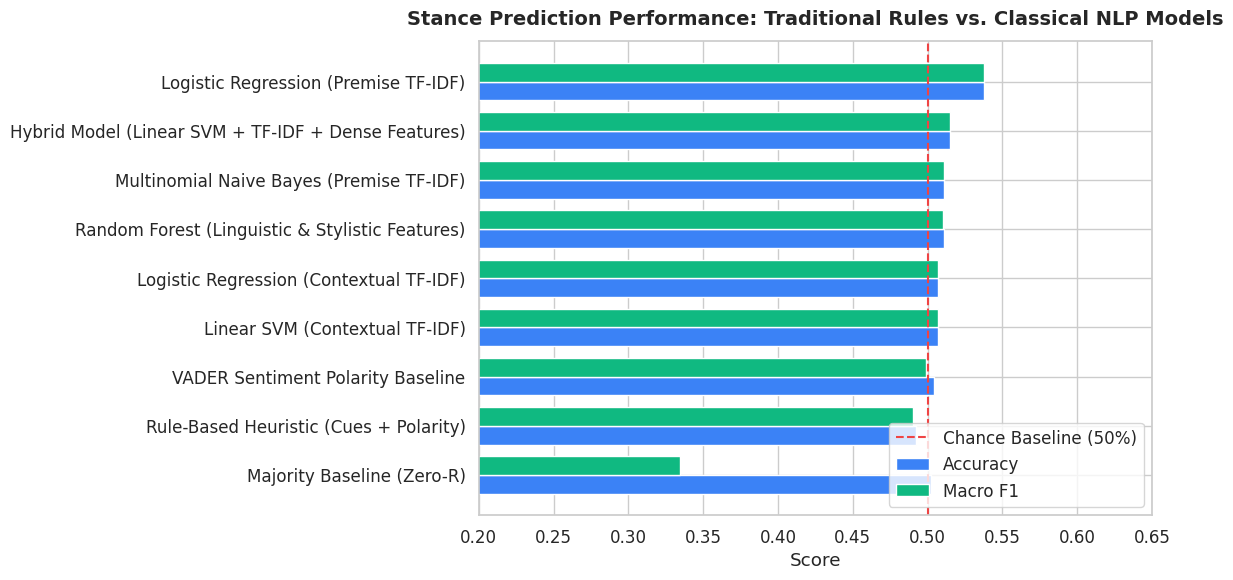

In [8]:
# 5. Visualize Model Comparison: Accuracy and Macro F1
fig, ax = plt.subplots(figsize=(12, 6))

plot_df = results_df.sort_values(by="Macro F1", ascending=True)
y_pos = np.arange(len(plot_df))
bar_width = 0.38

ax.barh(y_pos - bar_width/2, plot_df["Accuracy"], height=bar_width, label="Accuracy", color="#3b82f6")
ax.barh(y_pos + bar_width/2, plot_df["Macro F1"], height=bar_width, label="Macro F1", color="#10b981")

ax.axvline(0.50, color="#ef4444", linestyle="--", linewidth=1.5, label="Chance Baseline (50%)")
ax.set_yticks(y_pos)
ax.set_yticklabels(plot_df["Model"])
ax.set_xlabel("Score")
ax.set_xlim(0.20, 0.65)
ax.set_title("Stance Prediction Performance: Traditional Rules vs. Classical NLP Models", fontsize=14, fontweight="bold", pad=12)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

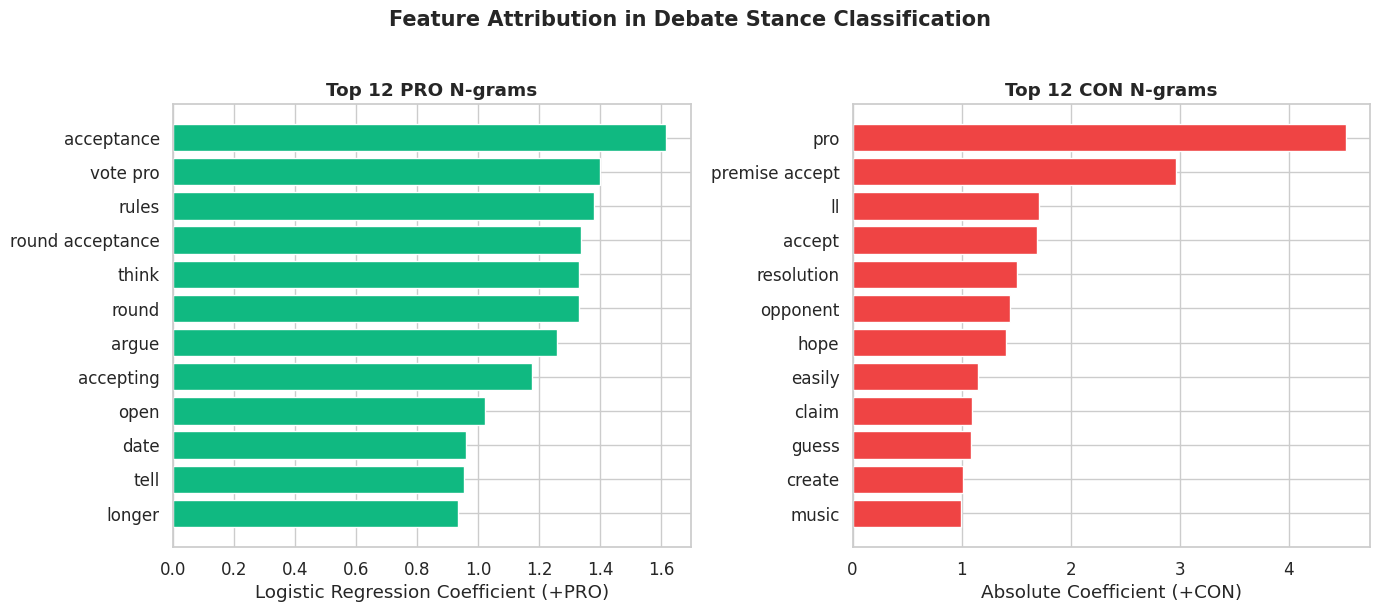

In [9]:
# 6. Interpretability: Top Positive (PRO) and Negative (CON) Lexical Coefficients
top_pro, top_con = runner.extract_top_features(df, n_top=12)

pro_words, pro_scores = zip(*top_pro)
con_words, con_scores = zip(*top_con)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

ax1.barh(range(len(pro_words)), pro_scores, color="#10b981")
ax1.set_yticks(range(len(pro_words)))
ax1.set_yticklabels(pro_words)
ax1.invert_yaxis()
ax1.set_xlabel("Logistic Regression Coefficient (+PRO)")
ax1.set_title("Top 12 PRO N-grams", fontweight="bold")

ax2.barh(range(len(con_words)), [abs(s) for s in con_scores], color="#ef4444")
ax2.set_yticks(range(len(con_words)))
ax2.set_yticklabels(con_words)
ax2.invert_yaxis()
ax2.set_xlabel("Absolute Coefficient (+CON)")
ax2.set_title("Top 12 CON N-grams", fontweight="bold")

plt.suptitle("Feature Attribution in Debate Stance Classification", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

In [10]:
# 7. Cross-Topic Generalization Assessment
oot_metrics = runner.run_cross_topic_generalization(df)
print("=== OUT-OF-TOPIC EVALUATION METRICS ===")
print(f"Model:           {oot_metrics.model_name}")
print(f"Accuracy:        {oot_metrics.accuracy:.4f}")
print(f"Macro F1:        {oot_metrics.macro_f1:.4f}")
print(f"Macro Precision: {oot_metrics.macro_precision:.4f}")
print(f"Macro Recall:    {oot_metrics.macro_recall:.4f}")
print(f"CON F1:          {oot_metrics.con_f1:.4f} | PRO F1: {oot_metrics.pro_f1:.4f}")

=== OUT-OF-TOPIC EVALUATION METRICS ===
Model:           Out-of-Topic Logistic Regression (Unseen Topics)
Accuracy:        0.5784
Macro F1:        0.5784
Macro Precision: 0.5785
Macro Recall:    0.5785
CON F1:          0.5748 | PRO F1: 0.5819


## Key Takeaways and Architectural Insights

1. **The Stance $\neq$ Sentiment Barrier**:
   - Pure sentiment polarity (VADER) achieves **50.4% accuracy**, functionally equivalent to random guessing. Debaters criticizing a proposal use negative words to support a `CON` stance, but debaters attacking a harmful status quo (e.g., arguing *against* pollution or *for* abolishing mandatory tests) also use intense negative vocabulary to argue a `PRO` stance.

2. **Adversarial Vocabulary & Quoting Trap**:
   - In online debate portals, `CON` debaters frequently cite their opponent (e.g., *"Pro claims that..."*), resulting in the word `"pro"` having the highest negative coefficient (`-4.66`) pointing toward the `CON` label! Shallow bag-of-words classifiers are heavily vulnerable to this discourse structure.

3. **Performance Plateau of Traditional Approaches**:
   - Across all tested traditional models (Rules, Naive Bayes, Logistic Regression, Linear SVM, and Random Forests), accuracy plateaus between **49.2% and 54.9%**.
   - This confirms that stance detection is fundamentally a **relational entailment problem** requiring deep contextual representations (e.g. cross-encoders or transformer attention mechanisms) to resolve the semantic relationship between conclusion and premise.